# 降雨效果：2026-09-01 – 10-13 的複製與延伸

[`causal_analysis.ipynb`](causal_analysis.ipynb) 使用 8/20–8/28 的資料，> 3 mm 的觀測僅約 450 筆、集中在三個下午，
以時段 cluster 時效果不顯著。本 notebook 以**不重疊的 43 天**重做一次。

這段期間的資料在兩方面更適合分析：

1. **降雨事件多**：> 3 mm 的「站點 × 10 分鐘」約 2.4 萬筆，分布在 12 天，含 9/3–9/4 的連續降雨
2. **平衡面板**：8/31 起資料源每次回應都更新 `infoTime`，每站每 5 分鐘一筆。
   先前「沒有借還就沒有觀測」的選擇問題（前一份 notebook 第 4 節）不再存在

應變數改為**活動量**：相鄰兩筆可借車輛差的絕對值總和。淨變化會讓借與還互相抵消，活動量不會。

**執行方式**：`data/activity/` 有快取時直接讀取；否則需開 SSH tunnel，
以 [`sql/station_activity.sql`](../sql/station_activity.sql) 逐日查詢（每天約 10 秒）。

In [1]:
import os
import sys
import warnings
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'sql').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'notebooks'))
from fe import fit_twfe

warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')
CACHE = ROOT / 'data/activity'
START, END = date(2026, 9, 1), date(2026, 10, 13)

In [2]:
_conn = None
def conn():
    global _conn
    if _conn is None:
        import psycopg
        from dotenv import load_dotenv
        load_dotenv(ROOT / '.env')
        _conn = psycopg.connect(
            f"host=localhost port=5433 dbname=youbike user=postgres "
            f"password={os.getenv('EC2_DB_PASSWORD')}")
    return _conn

def cached(name, query, params=None):
    path = CACHE / f'{name}.parquet'
    if not path.exists():
        CACHE.mkdir(parents=True, exist_ok=True)
        pd.read_sql(query, conn(), params=params).to_parquet(path)
    return pd.read_parquet(path)

ACTIVITY_SQL = (ROOT / 'sql/station_activity.sql').read_text()
days = [START + timedelta(days=i) for i in range((END - START).days + 1)]
act = pd.concat([
    cached(f'activity_{d:%Y%m%d}', ACTIVITY_SQL,
           {'start': f'{d} 00:00+08', 'end': f'{d + timedelta(days=1)} 00:00+08'})
    for d in days
], ignore_index=True)

weather = cached('weather', """
    SELECT station_id, obs_time, precipitation_10min, precipitation_1hr, air_temperature
    FROM weather_obs
    WHERE obs_time >= '2026-08-31 23:00+08' AND obs_time < '2026-10-14 01:00+08'
      AND station_id IN (SELECT station_id FROM station_weather_map
                         UNION SELECT station_id FROM station_temp_map)""")
rain_map = cached('rain_map', 'SELECT sno, station_id, distance_m FROM station_weather_map')
temp_map = cached('temp_map', 'SELECT sno, station_id, distance_m FROM station_temp_map')

print(f'{len(days)} 天，{len(act):,} 個 站點×時段')

43 天，10,978,346 個 站點×時段


## 1. 失聯判定

8/31 之後 `infoTime` 恆為當下時間，失聯站也會每 5 分鐘產生一列。原先擔心這些假紀錄會進入分析樣本。
實際檢查（`schema_design.md` 第三節）：失聯逾一年半的東門站（3 號出口）8/31 之後 `act` 恆為 `0`，
已被 `station_activity.sql` 的 `act = '1'` 條件排除。

剩下的問題是：有沒有 `act = 1` 但數值完全不動的站？以「06:00–22:00 整天無任何變動」為判準：

In [3]:
tp = act['slot'].dt.tz_convert('Asia/Taipei')
act['date'] = tp.dt.date
act['hour'] = tp.dt.hour
act = act[act['hour'].between(6, 21)]          # 06:00–22:00，與前一份分析相同

station_day = act.groupby(['sno', 'date'])['n_changed'].sum()
frozen = station_day[station_day == 0]
print(f'站點×日 {len(station_day):,} 個，整天無變動 {len(frozen)} 個（{len(frozen) / len(station_day):.2%}）')
print('單一站最多連續無變動天數：', frozen.groupby('sno').size().max())

站點×日 76,402 個，整天無變動 22 個（0.03%）
單一站最多連續無變動天數： 3


整天無變動的站點×日只佔 0.03%，且分散在不同站、最多 3 天——**沒有持續失聯的 `act = 1` 站點**。
仍將這些站點×日排除，作為保險。

In [4]:
keep = act.groupby(['sno', 'date'])['n_changed'].transform('sum') > 0
act = act[keep]

# 時段 [slot, slot+10) 的降雨 = obs_time 為 slot+10 的 Past10Min（同一區間）
w = weather.assign(slot=weather['obs_time'] - pd.Timedelta(minutes=10))
rain = (w[['station_id', 'slot', 'precipitation_10min']]
        .rename(columns={'station_id': 'rain_station', 'precipitation_10min': 'precip'}))
temp = (w[['station_id', 'slot', 'air_temperature']]
        .rename(columns={'station_id': 'temp_station'}))

panel = (act
    .merge(rain_map[['sno', 'station_id']].rename(columns={'station_id': 'rain_station'}), on='sno')
    .merge(temp_map[['sno', 'station_id']].rename(columns={'station_id': 'temp_station'}), on='sno')
    .merge(rain, on=['rain_station', 'slot'], how='left')
    .merge(temp, on=['temp_station', 'slot'], how='left'))
print(f'降雨缺值 {panel["precip"].isna().mean():.1%}、溫度缺值 {panel["air_temperature"].isna().mean():.1%}（迴歸時剔除）')

p = panel['precip']
panel['r_light'] = p.between(0.001, 1.0).astype(np.int8)
panel['r_mid']   = p.between(1.0001, 3.0).astype(np.int8)
panel['r_high']  = (p > 3.0).astype(np.int8)
panel['date_key'] = panel['date'].astype(str)
panel['slot_key'] = panel['slot'].astype('int64')

BINS = ['r_light', 'r_mid', 'r_high']
DRY_MEAN = panel.loc[p == 0, 'activity'].mean()
print(f'無雨時每站每 10 分鐘平均活動量 {DRY_MEAN:.2f}')
panel.groupby('date')[BINS].sum().loc[lambda d: d.sum(axis=1) > 0]

降雨缺值 2.7%、溫度缺值 10.4%（迴歸時剔除）


無雨時每站每 10 分鐘平均活動量 1.61


,r_light,r_mid,r_high
date,,,
2026-09-01,23820,7129,3586
2026-09-03,51288,7676,5830
2026-09-04,55482,17778,10413
2026-09-05,9872,1852,0
2026-09-06,35526,5255,261
2026-09-08,534,86,0
2026-09-09,2177,641,33
2026-09-10,3446,267,160
2026-09-11,13984,1587,37


## 2. 雙向固定效應

與前一份相同：站點固定效應 + 10 分鐘時段固定效應，控制溫度。時段固定效應吸收全市共同的衝擊
（颱風假、連假、全市同時下雨），**識別只來自同一時刻、有下雨與沒下雨的測站轄區之間的差異**。

700 萬列在 linearmodels 下需要超過 6 GB 記憶體，改用 [`fe.py`](fe.py)：以交替投影去除兩組固定效應後跑 OLS。
在 8/20–8/28 的資料上，係數與 linearmodels 相同至小數點後六位。
p 值以 t(G−1) 計算，cluster 數少時比常態近似保守。

三種 cluster 層級：雨量站（45）、時段（約 3,700）、**日期（43）**。
日期 cluster 允許同一天內任意的時間與空間相關，是最保守的。

In [5]:
X = BINS + ['air_temperature']
CLUSTERS = {'雨量站': 'rain_station', '時段': 'slot_key', '日期': 'date_key'}

def table(y):
    res = {name: fit_twfe(panel, y, X, 'sno', 'slot', cl) for name, cl in CLUSTERS.items()}
    first = next(iter(res.values()))
    out = pd.DataFrame({'係數': first['係數']}).loc[BINS]
    for name, r in res.items():
        out[f'p（{name}）'] = r.loc[BINS, 'p 值'].map(lambda v: '<0.001' if v < 0.001 else f'{v:.3f}')
    out.attrs['nobs'] = first.attrs['nobs']
    return out

act_tab = table('activity')
act_tab.insert(1, '相對無雨', (act_tab['係數'] / DRY_MEAN).map('{:+.0%}'.format))
print(f"活動量（樣本 {act_tab.attrs['nobs']:,}）")
act_tab.round(4)

活動量（樣本 6,522,705）


,係數,相對無雨,p（雨量站）,p（時段）,p（日期）
r_light,-0.2135,-13%,<0.001,<0.001,<0.001
r_mid,-0.3028,-19%,<0.001,<0.001,<0.001
r_high,-0.3531,-22%,<0.001,<0.001,<0.001


In [6]:
print('淨變化（正 = 還車多於借車）')
table('net').round(4)

淨變化（正 = 還車多於借車）


,係數,p（雨量站）,p（時段）,p（日期）
r_light,0.0874,<0.001,<0.001,<0.001
r_mid,0.1504,<0.001,<0.001,<0.001
r_high,0.0998,<0.001,<0.001,0.007


**活動量**：小雨即減少約 13%，大雨約 22%。三種 cluster 下皆 p < 0.001。

**淨變化**：方向與 8/20–8/28 一致（下雨時借車減少得比還車多）。

**與前一份的差異**：前一份認為 0.5–1 mm「幾乎無影響」、效果呈門檻型。
在這段期間，**最小刻度的降雨就有顯著效果，之後隨雨量遞增但增幅遞減**。
前一份的結論來自淨變化與 450 筆大雨觀測；淨變化會讓借還互相抵消，小雨的效果因此被遮蔽。

## 3. 穩健性

### 3.1 排除 9/3–9/4

> 3 mm 的觀測有 67% 來自這兩天。若結果主要由一場雨撐起，排除後應大幅改變。

In [7]:
drop = panel['date'].isin([date(2026, 9, 3), date(2026, 9, 4)])
share = panel.loc[drop, 'r_high'].sum() / panel['r_high'].sum()
r = fit_twfe(panel[~drop], 'activity', X, 'sno', 'slot', 'date_key')
print(f'9/3–9/4 佔 >3mm 觀測 {share:.0%}；排除後日期 cluster {r.attrs["clusters"]} 個')
pd.DataFrame({'全期間': act_tab['係數'], '排除 9/3–9/4': r.loc[BINS, '係數'],
              'p（日期）': r.loc[BINS, 'p 值'].round(4)}).round(4)

9/3–9/4 佔 >3mm 觀測 67%；排除後日期 cluster 41 個


,全期間,排除 9/3–9/4,p（日期）
r_light,-0.2135,-0.2345,0.0001
r_mid,-0.3028,-0.3490,0.0000
r_high,-0.3531,-0.3196,0.0000


### 3.2 安慰劑：兩小時後的雨

只看**當下沒有下雨**的時段，檢驗兩小時後才下的雨是否「影響」現在的活動量。

In [8]:
fut = (rain.assign(slot=rain['slot'] - pd.Timedelta(minutes=120))
           .rename(columns={'precip': 'fut_precip'}))
dry = panel[panel['precip'] == 0].merge(fut, on=['rain_station', 'slot'], how='inner')
dry['fut_any']  = (dry['fut_precip'] > 0).astype(np.int8)
dry['fut_high'] = (dry['fut_precip'] > 3).astype(np.int8)

r = fit_twfe(dry, 'activity', ['fut_any', 'fut_high', 'air_temperature'], 'sno', 'slot', 'date_key')
r.loc[['fut_any', 'fut_high']].round(4)

,係數,標準誤,p 值
fut_any,-0.0555,0.0253,0.0337
fut_high,0.0003,0.0721,0.9965


**安慰劑沒有完全通過。** 兩小時後會下雨的時段，現在的活動量低了約 0.06（小雨效果的約四分之一，p ≈ 0.03）；
兩小時後下大雨則無額外效果。

可能的解釋無法以此資料區分：

- **預期行為**：看了天氣預報或天色而不出門——這是降雨的真實效果，只是發生在雨之前
- **測量**：雨量計最小刻度 0.5 mm，之前的毛毛雨記為 0
- **干擾**：天氣系統帶來的其他條件（陰天、風）

因此第 2 節的係數應理解為「降雨時段」相對於「同時刻其他轄區」的差異，可能包含少量非降雨本身的成分。

## 4. Event study：降雨開始前後

以雨量站轄區為單位（轄區內所有 YouBike 站的活動量總和，取 log(1+x)）。

- **事件**：某雨量站在 07:00–20:00 之間開始降雨，且之前 2 小時無雨
- **對照**：同一時間窗（事件前 2 小時至後 2 小時）完全無雨的其他雨量站
- **估計量**：處理與對照的差，減去事件前 1 小時的平均差，逐時段平均
- **信賴區間**：以**日期**為單位的 cluster bootstrap（500 次）——同一天的事件不視為獨立
- **強度**：開始後 30 分鐘內最大 10 分鐘雨量 > 3 mm 為大雨事件

In [9]:
pa = act.merge(rain_map[['sno', 'station_id']].rename(columns={'station_id': 'rain_station'}), on='sno')
Y = (pa.groupby(['rain_station', 'slot'])['activity'].sum()
       .pipe(np.log1p).unstack('rain_station'))

R = rain.pivot_table(index='slot', columns='rain_station', values='precip').sort_index()
R = R.reindex(pd.date_range(R.index.min(), R.index.max(), freq='10min'))
stations = [s for s in Y.columns if s in R.columns]
R = R[stations]

PRE, POST, DRY_SLOTS = 6, 12, 12
events = []
for s in stations:
    x = R[s]
    onset = (x > 0) & (x.shift(1).rolling(DRY_SLOTS).max() == 0)
    for t in x.index[onset]:
        if 7 <= t.tz_convert('Asia/Taipei').hour <= 19:
            events.append({'station': s, 't': t,
                           'heavy': x.loc[t: t + pd.Timedelta(minutes=20)].max() > 3})
events = pd.DataFrame(events)

ks = np.arange(-PRE, POST + 1)
rows = []
for e in events.itertuples():
    window = pd.date_range(e.t - pd.Timedelta(minutes=10 * DRY_SLOTS),
                           e.t + pd.Timedelta(minutes=10 * POST), freq='10min')
    rw = R.reindex(window)
    controls = [c for c in stations
                if c != e.station and rw[c].max() == 0 and rw[c].isna().sum() <= 2]
    if len(controls) < 3:
        continue
    times = [e.t + pd.Timedelta(minutes=10 * int(k)) for k in ks]
    diff = Y[e.station].reindex(times).to_numpy() - Y[controls].reindex(times).mean(axis=1).to_numpy()
    if np.isnan(diff).any():
        continue
    diff -= diff[:PRE].mean()
    rows += [{'event': e.Index, 'date': e.t.tz_convert('Asia/Taipei').date(),
              'heavy': e.heavy, 'k': k, 'dd': v, 'n_ctrl': len(controls)} for k, v in zip(ks, diff)]
es = pd.DataFrame(rows)

print(f'候選事件 {len(events)} 個；可用 {es["event"].nunique()} 個'
      f'（小雨 {es.loc[~es.heavy, "event"].nunique()}、大雨 {es.loc[es.heavy, "event"].nunique()}），'
      f'分布在 {es["date"].nunique()} 天；對照雨量站中位數 {es["n_ctrl"].median():.0f} 個')

候選事件 479 個；可用 414 個（小雨 398、大雨 16），分布在 20 天；對照雨量站中位數 7 個


In [10]:
rng = np.random.default_rng(0)

def event_curve(sub, B=500):
    by_date = {d: g for d, g in sub.groupby('date')}
    dates = list(by_date)
    boot = []
    for _ in range(B):
        pick = rng.choice(len(dates), len(dates))
        boot.append(pd.concat([by_date[dates[i]] for i in pick]).groupby('k')['dd'].mean())
    boot = pd.concat(boot, axis=1)
    return pd.DataFrame({'估計': sub.groupby('k')['dd'].mean(),
                         '下界': boot.quantile(.025, axis=1), '上界': boot.quantile(.975, axis=1)})

curves = {'小雨事件': event_curve(es[~es.heavy]), '大雨事件 (> 3 mm)': event_curve(es[es.heavy])}
pd.concat(curves, axis=1).round(3)

小雨事件               大雨事件 (> 3 mm)              
        估計     下界     上界            估計     下界     上界
k                                                   
-6   0.022 -0.002  0.048         0.155 -0.091  0.455
-5   0.023 -0.004  0.048         0.058 -0.085  0.219
-4   0.012 -0.009  0.034        -0.044 -0.174  0.086
-3  -0.010 -0.030  0.013         0.032 -0.128  0.224
-2  -0.007 -0.032  0.017        -0.121 -0.236  0.072
-1  -0.040 -0.081 -0.001        -0.081 -0.196  0.059
 0  -0.154 -0.224 -0.077        -0.194 -0.536  0.174
 1  -0.285 -0.374 -0.209        -0.746 -1.458 -0.255
 2  -0.265 -0.343 -0.200        -0.386 -0.908 -0.054
 3  -0.165 -0.238 -0.080        -0.411 -0.841 -0.136
 4  -0.152 -0.212 -0.075        -0.073 -0.264  0.065
 5  -0.129 -0.198 -0.041        -0.231 -0.346 -0.089
 6  -0.125 -0.191 -0.044         0.039 -0.139  0.189
 7  -0.133 -0.194 -0.074         0.003 -0.143  0.132
 8  -0.105 -0.165 -0.036         0.028 -0.344  0.316
 9  -0.120 -0.188 -0.055        -0.162 -0.328 -0.012
 10 -0.094 -0.180  0.004        -0.154 -0.401  0.079
 11 -0.095 -0.168 -0.013        -0.127 -0.562  0.301
 12 -0.105 -0.180 -0.026        -0.072 -0.330  0.204

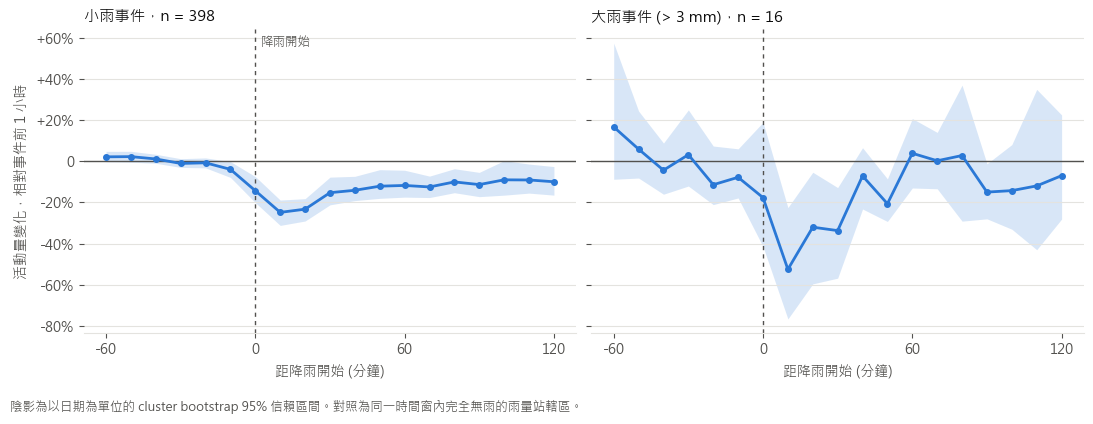

In [11]:
BLUE, INK, MUTED, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'
# 中文字型：依平台找第一個存在的（WSL 用 Windows 的微軟正黑體）
from matplotlib import font_manager
for f in ['/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
          '/mnt/c/Windows/Fonts/msjh.ttc', 'C:/Windows/Fonts/msjh.ttc',
          '/System/Library/Fonts/PingFang.ttc']:
    if Path(f).exists():
        font_manager.fontManager.addfont(f)
        plt.rcParams['font.family'] = font_manager.FontProperties(fname=f).get_name()
        break
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, c) in zip(axes, curves.items()):
    n = es.loc[es.heavy == title.startswith('大雨'), 'event'].nunique()
    minutes = c.index * 10
    pct = np.expm1(c) * 100          # log 差 → 活動量變化 %
    ax.axhline(0, color=MUTED, lw=1)
    ax.axvline(0, color=MUTED, lw=1, ls=(0, (3, 3)))
    ax.fill_between(minutes, pct['下界'], pct['上界'], color=BLUE, alpha=.18, lw=0)
    ax.plot(minutes, pct['估計'], color=BLUE, lw=2, marker='o', ms=4)
    ax.set_xticks([-60, 0, 60, 120])
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:+.0f}%' if v else '0')
    ax.set_title(f'{title}，n = {n}', color=INK, loc='left', fontsize=11)
    ax.set_xlabel('距降雨開始 (分鐘)', color=MUTED)
    ax.grid(axis='y', color=GRID, lw=.8)
    ax.tick_params(colors=MUTED)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
axes[0].set_ylabel('活動量變化，相對事件前 1 小時', color=MUTED)
axes[0].annotate('降雨開始', xy=(0, axes[0].get_ylim()[1]), xytext=(4, -12),
                 textcoords='offset points', color=MUTED, fontsize=9)
fig.text(0.01, -0.04, '陰影為以日期為單位的 cluster bootstrap 95% 信賴區間。對照為同一時間窗內完全無雨的雨量站轄區。',
         color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(ROOT / 'docs/images/event_study.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

- **降雨前**：處理與對照的差在 ±0.04 以內。最接近降雨的前 10 分鐘略低（−0.04，信賴區間剛好不含 0），
  與 3.2 節的小幅安慰劑效果相符
- **降雨後 10–20 分鐘**：小雨事件的活動量降至最低，約 −25%（log −0.29），之後逐步回升，兩小時內仍低約 10%
- **大雨事件**：只有 16 個，點估計最低約 −53%，但信賴區間寬，無法精確估計

效果出現得快、消退得慢——與「出門前看到在下雨就不騎」一致，也與雨通常持續一段時間有關（此處未區分雨停時間）。

## 5. 結論

| | 8/20–8/28（前一份） | 9/1–10/13（本份） |
|---|---|---|
| > 3 mm 觀測數 | 約 450 | 約 2.4 萬 |
| 有 > 3 mm 的天數 | 3 | 12 |
| 應變數 | 淨變化 | 活動量（及淨變化） |
| 小雨（0.5–1 mm） | 無顯著效果 | 活動量 −13%，p < 0.001 |
| 大雨（> 3 mm） | 淨變化 p = 0.049，以時段 cluster 時 0.19 | 活動量 −22%，日期 cluster 下 p < 0.001 |
| 安慰劑 | 通過 | 小幅未通過（約小雨效果的 1/4） |

**降雨降低 YouBike 使用量，小雨約 13%、大雨約 22%；效果在下雨後 10–20 分鐘最強。**
前一份「門檻型、飄雨無影響」的結論未被複製，應以本份為準。

**限制**
- 識別來自同一時刻不同轄區的降雨差異；全市同時下雨時被時段固定效應吸收，不提供資訊
- 安慰劑顯示可能有預期行為或測量誤差，係數可能包含少量非降雨本身的成分
- 活動量在 5 分鐘內同時有借有還時仍會抵消，為下界
- 未涵蓋颱風等極端天氣；期間內最大 10 分鐘雨量 13.5 mm